# Escolha dos Modelos

## 1. Imports necessários
Manteremos a divisão do nosso trabalho na proporção 70%/15%/15%

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from time import perf_counter
from IPython.display import display

from saikit_learn.preprocessing import StandardScaler
from saikit_learn.linear_model import LogisticRegression
from saikit_learn.neighbors import KNN
from saikit_learn.discriminant_analysis import LDA, QDA
from saikit_learn.classification_metrics import ClassificationMetrics


## 2. Mesmos dados e pré-processamento
Repetimos as operações do preprocessamento.ipynb para que este notebook
possa ser executado de forma independente. Os rótulos são convertidos para
vetores NumPy, exigidos por KNN, LDA, QDA e pela classe de métricas.

In [5]:
raiz = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'data/raw/magic04.data').is_file()),
    None
)
if raiz is None:
    raise FileNotFoundError('Execute este notebook dentro do repositório saikit-learn-aplicacao.')

columns = [
    'fLength', 'fWidth', 'fSize', 'fConc', 'fConc1',
    'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class'
]
df = pd.read_csv(raiz / 'data/raw/magic04.data', header=None, names=columns)
X = df.drop(columns='class').to_numpy(dtype=float)
y = df['class'].str.strip().map({'g': 1, 'h': 0}).to_numpy(dtype=int)

indices = np.random.RandomState(42).permutation(len(X))
train_end = int(len(X) * 0.70)
val_end = int(len(X) * 0.85)

train_indices = indices[:train_end]
val_indices = indices[train_end:val_end]
test_indices = indices[val_end:]

X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print('Treino:', X_train_scaled.shape, '| Validação:', X_val_scaled.shape)
print('Teste reservado:', X_test_scaled.shape)


Treino: (13314, 10) | Validação: (2853, 10)
Teste reservado: (2853, 10)


In [7]:
modelos = {
    'Logística': LogisticRegression(),
    'KNN (k=5)': KNN(k=5),
    'LDA': LDA(),
    'QDA': QDA(),
}


In [8]:
resultados = []
matrizes = {}

for nome, modelo in modelos.items():
    inicio = perf_counter()
    modelo.fit(X_train_scaled, y_train)
    tempo_treino = perf_counter() - inicio

    inicio = perf_counter()
    predicoes = modelo.predict(X_val_scaled)
    tempo_previsao = perf_counter() - inicio

    metricas = ClassificationMetrics(y_val, predicoes, labels=[0, 1])
    matriz = metricas.confusion_matrix()
    matrizes[nome] = matriz

    tn, fp, fn, tp = matriz.ravel()
    resultados.append({
        'modelo': nome,
        'acuracia': metricas.score('accuracy'),
        'precisao_gamma': metricas.score('precision', pos_label=1),
        'recall_gamma': metricas.score('recall', pos_label=1),
        'f1_gamma': metricas.score('f1', pos_label=1),
        'f1_macro': metricas.score('f1', average='macro'),
        'fpr_hadron': fp / (fp + tn),
        'tempo_treino_s': tempo_treino,
        'tempo_previsao_s': tempo_previsao,
    })
    print(f'{nome}: concluído')

tabela = pd.DataFrame(resultados).sort_values('f1_macro', ascending=False)
display(tabela.round(4))

logistica = modelos['Logística']
print('Logística — iterações:', logistica.n_iter_, '| Convergiu:', logistica.converged_)


Logística: concluído
KNN (k=5): concluído
LDA: concluído
QDA: concluído


,modelo,acuracia,precisao_gamma,recall_gamma,f1_gamma,f1_macro,fpr_hadron,tempo_treino_s,tempo_previsao_s
0,Logística,0.7753,0.7905,0.8813,0.8335,0.7441,0.4114,4.0847,0.0085
3,QDA,0.7869,0.7740,0.9407,0.8492,0.7430,0.4840,0.0034,0.0030
2,LDA,0.7669,0.7764,0.8912,0.8299,0.7299,0.4521,0.0066,0.0503
1,KNN (k=5),0.7199,0.9134,0.6198,0.7385,0.7185,0.1036,0.0010,8.3067


Logística — iterações: [3978] | Convergiu: [ True]


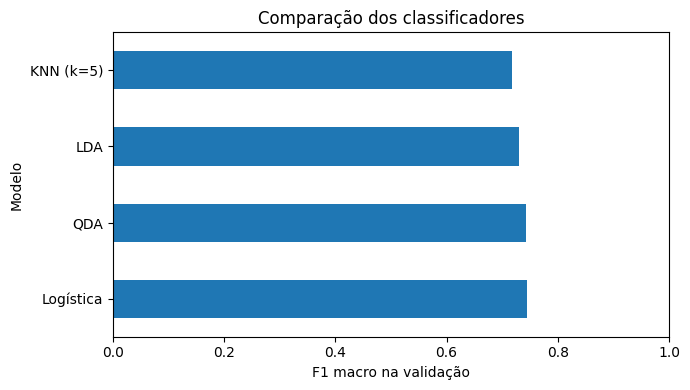

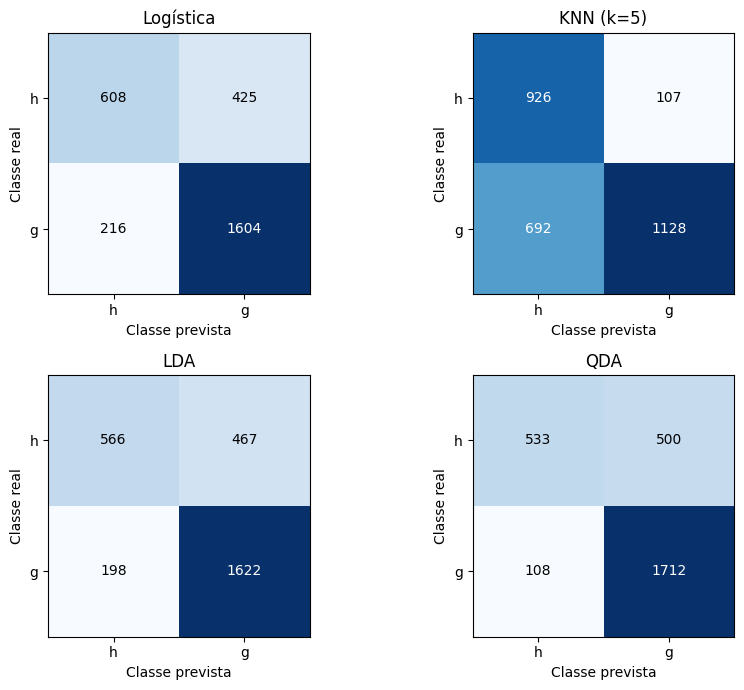

In [9]:
tabela.plot.barh(x='modelo', y='f1_macro', legend=False, figsize=(7, 4))
plt.xlabel('F1 macro na validação')
plt.ylabel('Modelo')
plt.xlim(0, 1)
plt.title('Comparação dos classificadores')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for ax, (nome, matriz) in zip(axes.ravel(), matrizes.items()):
    ax.imshow(matriz, cmap='Blues')
    for i in range(2):
        for j in range(2):
            cor = 'white' if matriz[i, j] > matriz.max() / 2 else 'black'
            ax.text(j, i, f'{matriz[i, j]:.0f}', ha='center', va='center', color=cor)
    ax.set_xticks([0, 1], ['h', 'g'])
    ax.set_yticks([0, 1], ['h', 'g'])
    ax.set(xlabel='Classe prevista', ylabel='Classe real', title=nome)
fig.tight_layout()
plt.show()


In [10]:
import json

pasta_resultados = raiz / 'analysis/classificacao/resultados'
pasta_resultados.mkdir(parents=True, exist_ok=True)
tabela.to_csv(pasta_resultados / 'metricas_validacao.csv', index=False)

for nome, matriz in matrizes.items():
    pd.DataFrame(
        matriz,
        index=['real_h', 'real_g'],
        columns=['previsto_h', 'previsto_g']
    ).to_csv(pasta_resultados / f'matriz_{nome.split()[0].lower()}.csv')

configuracao = {
    'semente': 42,
    'proporcoes': {'treino': 0.70, 'validacao': 0.15, 'teste': 0.15},
    'classes': {'h': 0, 'g': 1},
    'logistica': {
        'learning_rate': logistica.learning_rate,
        'max_iter': logistica.max_iter,
        'tol': logistica.tol,
        'alpha': logistica.alpha,
        'n_iter': logistica.n_iter_.tolist(),
        'converged': logistica.converged_.tolist(),
    },
    'knn': {'k': 5, 'p': 2},
    'qda': {'reg_param': modelos['QDA'].reg_param},
    'criterio_inicial': 'f1_macro na validacao',
}
(pasta_resultados / 'configuracao.json').write_text(
    json.dumps(configuracao, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Resultados salvos em:', pasta_resultados)


Resultados salvos em: c:\Users\hanni\OneDrive\Documentos\IMPATECH\saikit-learn-aplicacao\analysis\classificacao\resultados
